# JSONBench: larger EC2 server results

Analysis of the native **c8i.4xlarge (16 vCPU / 32 GiB)** experiment. Both databases had a **12 GiB service cap**; MongoDB cache 6 GiB, Couchbase Data 4 GiB / Index 2 GiB. The runner shared the host. This is one host, three sequential workload repetitions per configuration—not three independent machines.

**Recommended paper layout:** two metric rows × three scale-factor columns, client count on x. Keep backend, SF and clients separate; summarise only repetitions. Companion failure-rate panels are essential. Companion views below show successful query counts and failure heatmaps.

This notebook reads the downloaded artifacts without changing them. All outputs go to `analysis/ec2-large-figures`. Run from the repository or notebooks directory. Requires pandas, numpy, matplotlib and a Jupyter Python kernel. The data download is not included in Git.

**Caveats:** Couchbase experienced query-engine OOM kills. “Complete” means the benchmark recorded a completed run, not uninterrupted database operation. Successful-query latency excludes failed queries and is subject to survivorship bias. Mixed-workload means also reflect the realised query mix; inspect the per-query table before attributing changes to individual-query performance.

In [1]:
from pathlib import Path
import json, re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jsonbench/matrix.py").exists())
DATA = ROOT / "analysis/ec2-large-results/paper-v1"
OUT = ROOT / "analysis/ec2-large-figures"
OUT.mkdir(parents=True, exist_ok=True)
assert DATA.exists(), f"Missing downloaded results: {DATA}"
plt.rcParams.update(
    {
        "figure.dpi": 200,
        "savefig.dpi": 200,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "savefig.bbox": "tight",
    }
)
COLORS = {"mongodb": "#2166ac", "couchbase": "#b35806"}
LABELS = {"mongodb": "MongoDB", "couchbase": "Couchbase"}
SCALES = [10, 100, 200]
CLIENTS = [2, 4, 8, 16, 32, 64]


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200)
    fig.savefig(OUT / f"{name}.pdf")
    plt.show()


## Metric definitions and integrity checks

- **Throughput:** successful completions inside the measurement interval divided by its 180 seconds. This includes warm-up-started queries finishing during measurement and excludes late completions.
- **Latency:** mean duration of successful attempts **started during measurement**, including drained completions. It is not reciprocal throughput.
- **Failure rate:** errors + timeouts divided by completed attempts **started during measurement**, including drain. Timeout and error classifications are retained unchanged.
- Lines are unweighted means of the three run-level metrics; shading is their **minimum–maximum range**, not a confidence interval. Dots show individual repetitions. No pooling across SF or client count.
- OOM correlation uses the full attempt interval (including preparation/verification), not a claimed exact timed-measurement overlap. Kernel timestamps have second resolution. The run metadata does not save the wall-clock workload origin.


In [2]:
plan = json.loads((DATA / "plan.json").read_text())
state = json.loads((DATA / "state.json").read_text())
# One canonical kernel snapshot; do not concatenate overlapping snapshots and double-count kills.
kernel = (DATA / "kernel-20261110T2215.log").read_text()
oom_times = []
for line in kernel.splitlines():
    if "Killed process" in line and "(cbq-engine)" in line:
        stamp = datetime.strptime("2026 " + line[:15], "%Y %b %d %H:%M:%S").replace(tzinfo=timezone.utc)
        oom_times.append(stamp.timestamp())
rows, query_rows, audit = [], [], []
for cell in plan["cells"]:
    history = state["attempts"].get(cell["id"], [])
    assert history and history[-1]["state"] == "complete", f"Incomplete: {cell['id']}"
    attempt = history[-1]
    # Recorded paths refer to EC2; relocate only the suffix under attempts/.
    relative = attempt["run_path"].split("/attempts/", 1)[1]
    run = DATA / "attempts" / relative
    info = json.loads((run / "info.json").read_text())
    summary = json.loads((run / "summary.json").read_text())
    events = [json.loads(line) for line in (run / "events.jsonl").open()]
    completed = [e for e in events if e["event"] == "completed"]
    start, end = info["warmup_seconds"], info["warmup_seconds"] + info["measurement_seconds"]
    admitted = [e for e in completed if start <= e["start_seconds"] < end]
    starts = {e["attempt_id"] for e in events if e["event"] == "started"}
    finishes = {e["attempt_id"] for e in completed}
    assert starts == finishes and len(finishes) == len(completed), cell["id"]
    success = [e for e in admitted if e["status"] == "success"]
    throughput = (
        sum(e["status"] == "success" and start <= e["finish_seconds"] < end for e in completed)
        / info["measurement_seconds"]
    )
    assert np.isclose(throughput, summary["successful_completion_throughput_qps"])
    for status, key in [
        ("success", "measurement_successes"),
        ("timeout", "measurement_timeouts"),
        ("error", "measurement_errors"),
    ]:
        assert sum(e["status"] == status for e in admitted) == summary[key]
    latency = np.mean([e["time"] for e in success]) if success else np.nan
    assert (not success and summary["measurement_success_mean_seconds"] is None) or np.isclose(
        latency, summary["measurement_success_mean_seconds"]
    )
    kills = sum(attempt["started_at"] <= t <= attempt["finished_at"] for t in oom_times)
    row = dict(
        cell=cell["id"],
        backend=cell["backend"],
        sf=cell["scale_factor"],
        clients=cell["workers"],
        repetition=cell["repetition"],
        throughput_qps=throughput,
        successful_latency_s=latency,
        admitted=len(admitted),
        successes=len(success),
        timeouts=summary["measurement_timeouts"],
        errors=summary["measurement_errors"],
        oom_kills=kills,
        oom_affected=kills > 0,
        attempt_count=len(history),
    )
    row["failure_pct"] = 100 * (row["timeouts"] + row["errors"]) / len(admitted) if admitted else np.nan
    rows.append(row)
    for name in sorted({e["name"] for e in completed}):
        es = [e for e in admitted if e["name"] == name]
        ok = [e["time"] for e in es if e["status"] == "success"]
        query_rows.append(
            {
                **{k: row[k] for k in ["cell", "backend", "sf", "clients", "repetition", "oom_affected"]},
                "query": name,
                "attempts": len(es),
                "successes": len(ok),
                "timeouts": sum(e["status"] == "timeout" for e in es),
                "errors": sum(e["status"] == "error" for e in es),
                "successful_latency_s": np.mean(ok) if ok else np.nan,
            }
        )
    audit.append({"cell": cell["id"], "dataset_hash": info["dataset_manifest_sha256"], "revision": info["revision"]})
runs = pd.DataFrame(rows)
per_query = pd.DataFrame(query_rows)
assert len(runs) == 108
assert runs.groupby(["backend", "sf", "clients"]).size().eq(3).all()
assert len({a["revision"] for a in audit}) == 1
for sf in SCALES:
    assert len({a["dataset_hash"] for a in audit if a["cell"] in set(runs.loc[runs.sf == sf, "cell"])}) == 1
runs.to_csv(OUT / "run_metrics.csv", index=False)
per_query.to_csv(OUT / "per_query_metrics.csv", index=False)
display(
    runs.groupby("backend").agg(
        runs=("cell", "size"),
        timeouts=("timeouts", "sum"),
        errors=("errors", "sum"),
        oom_affected_runs=("oom_affected", "sum"),
        attributed_oom_kills=("oom_kills", "sum"),
    )
)
print(f"Kernel kills: {len(oom_times)}; attributed to attempt intervals: {runs.oom_kills.sum()}")


,runs,timeouts,errors,oom_affected_runs,attributed_oom_kills
backend,,,,,
couchbase,54,1870,6012,12,81
mongodb,54,1000,0,0,0


Kernel kills: 81; attributed to attempt intervals: 81


## Option A — recommended main paper figure

Columns fix scale factor; x varies client count. This makes saturation and latency growth easy to compare without conflating dataset size and concurrency. Both metrics use log y-axes to accommodate orders of magnitude. OOM markers are omitted here and retained in the companion failure diagrams. The LaTeX caption should state that throughput counts successful completions, latency includes successful queries only, and all runs (including OOM-affected runs) are retained. Null latency (no successes) is omitted, not plotted as zero. Always read this alongside the failure panels below.

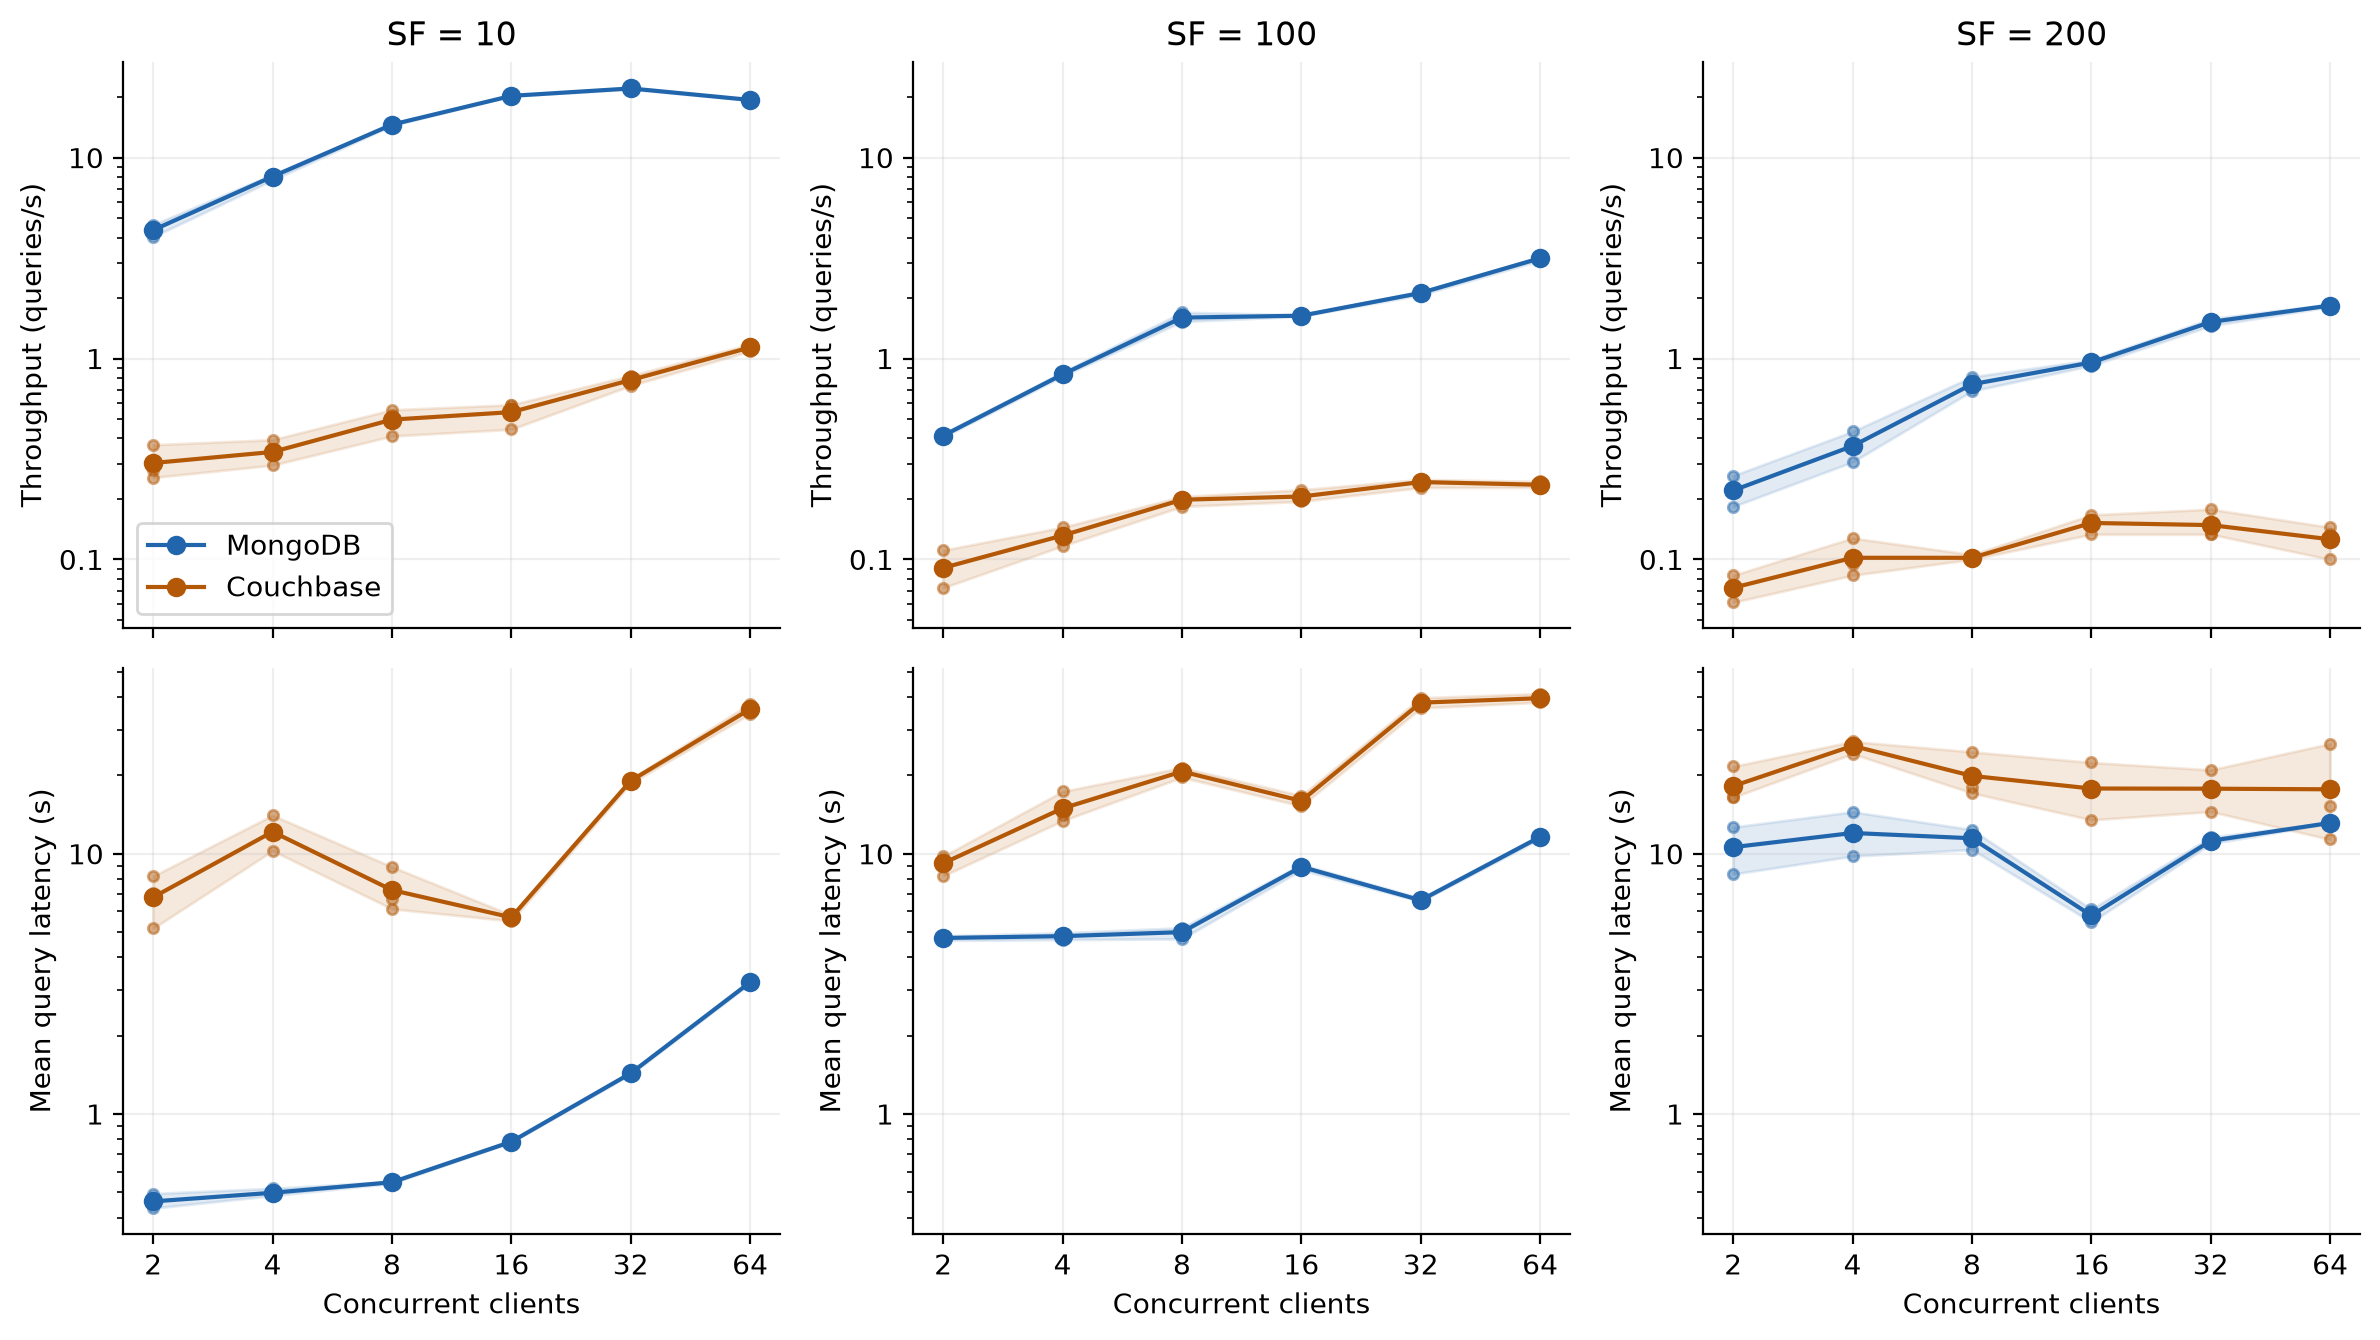

In [3]:
def draw(ax, data, x, metric, mark_oom=True):
    for backend, color in COLORS.items():
        d = data[data.backend == backend]
        g = d.groupby(x)[metric].agg(["mean", "min", "max"])
        ax.plot(g.index, g["mean"], marker="o", color=color, label=LABELS[backend])
        ax.fill_between(g.index.to_numpy(), g["min"].to_numpy(), g["max"].to_numpy(), color=color, alpha=0.13)
        ax.scatter(d[x], d[metric], color=color, alpha=0.5, s=14)
        bad = d[d.oom_affected]
        if mark_oom:
            ax.scatter(bad[x], bad[metric], color="black", marker="x", s=45, zorder=5)
    ax.grid(alpha=0.2)


fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), sharex=True, sharey="row")
for j, sf in enumerate(SCALES):
    for i, metric in enumerate(["throughput_qps", "successful_latency_s"]):
        ax = axes[i, j]
        draw(ax, runs[runs.sf == sf], "clients", metric, mark_oom=False)
        ax.set_xscale("log", base=2)
        ax.set_xticks(CLIENTS, labels=CLIENTS)
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:g}"))
        if i == 0:
            ax.set_title(f"SF = {sf}")
        else:
            ax.set_xlabel("Concurrent clients")
for ax in axes[0]:
    ax.set_ylabel("Throughput (queries/s)")
    ax.tick_params(axis="y", labelleft=True)
for ax in axes[1]:
    ax.set_ylabel("Mean query latency (s)")
    ax.tick_params(axis="y", labelleft=True)
axes[0, 0].legend()
fig.tight_layout()
save(fig, "clients_by_scale")


## Query outcomes by configuration — 100% stacked bars

Six panels separate MongoDB (top row) and Couchbase (bottom row), with one column per scale factor. Each panel has one bar per client count. Each bar totals100%, split into success, failure (non-timeout error), and timeout. For each repetition, percentages use completed attempts **started during measurement**, including drained finishes. The bars show the unweighted mean of the three repetition percentages. Unlike the throughput-count figure, this uses admission-based outcomes rather than completions inside the fixed window. All108 runs have matching started/completed events, verified above.

“Failure” in this figure means the recorded **error** category only; timeouts are separate. The failure-rate heatmap combines both. OOM-affected runs remain included.


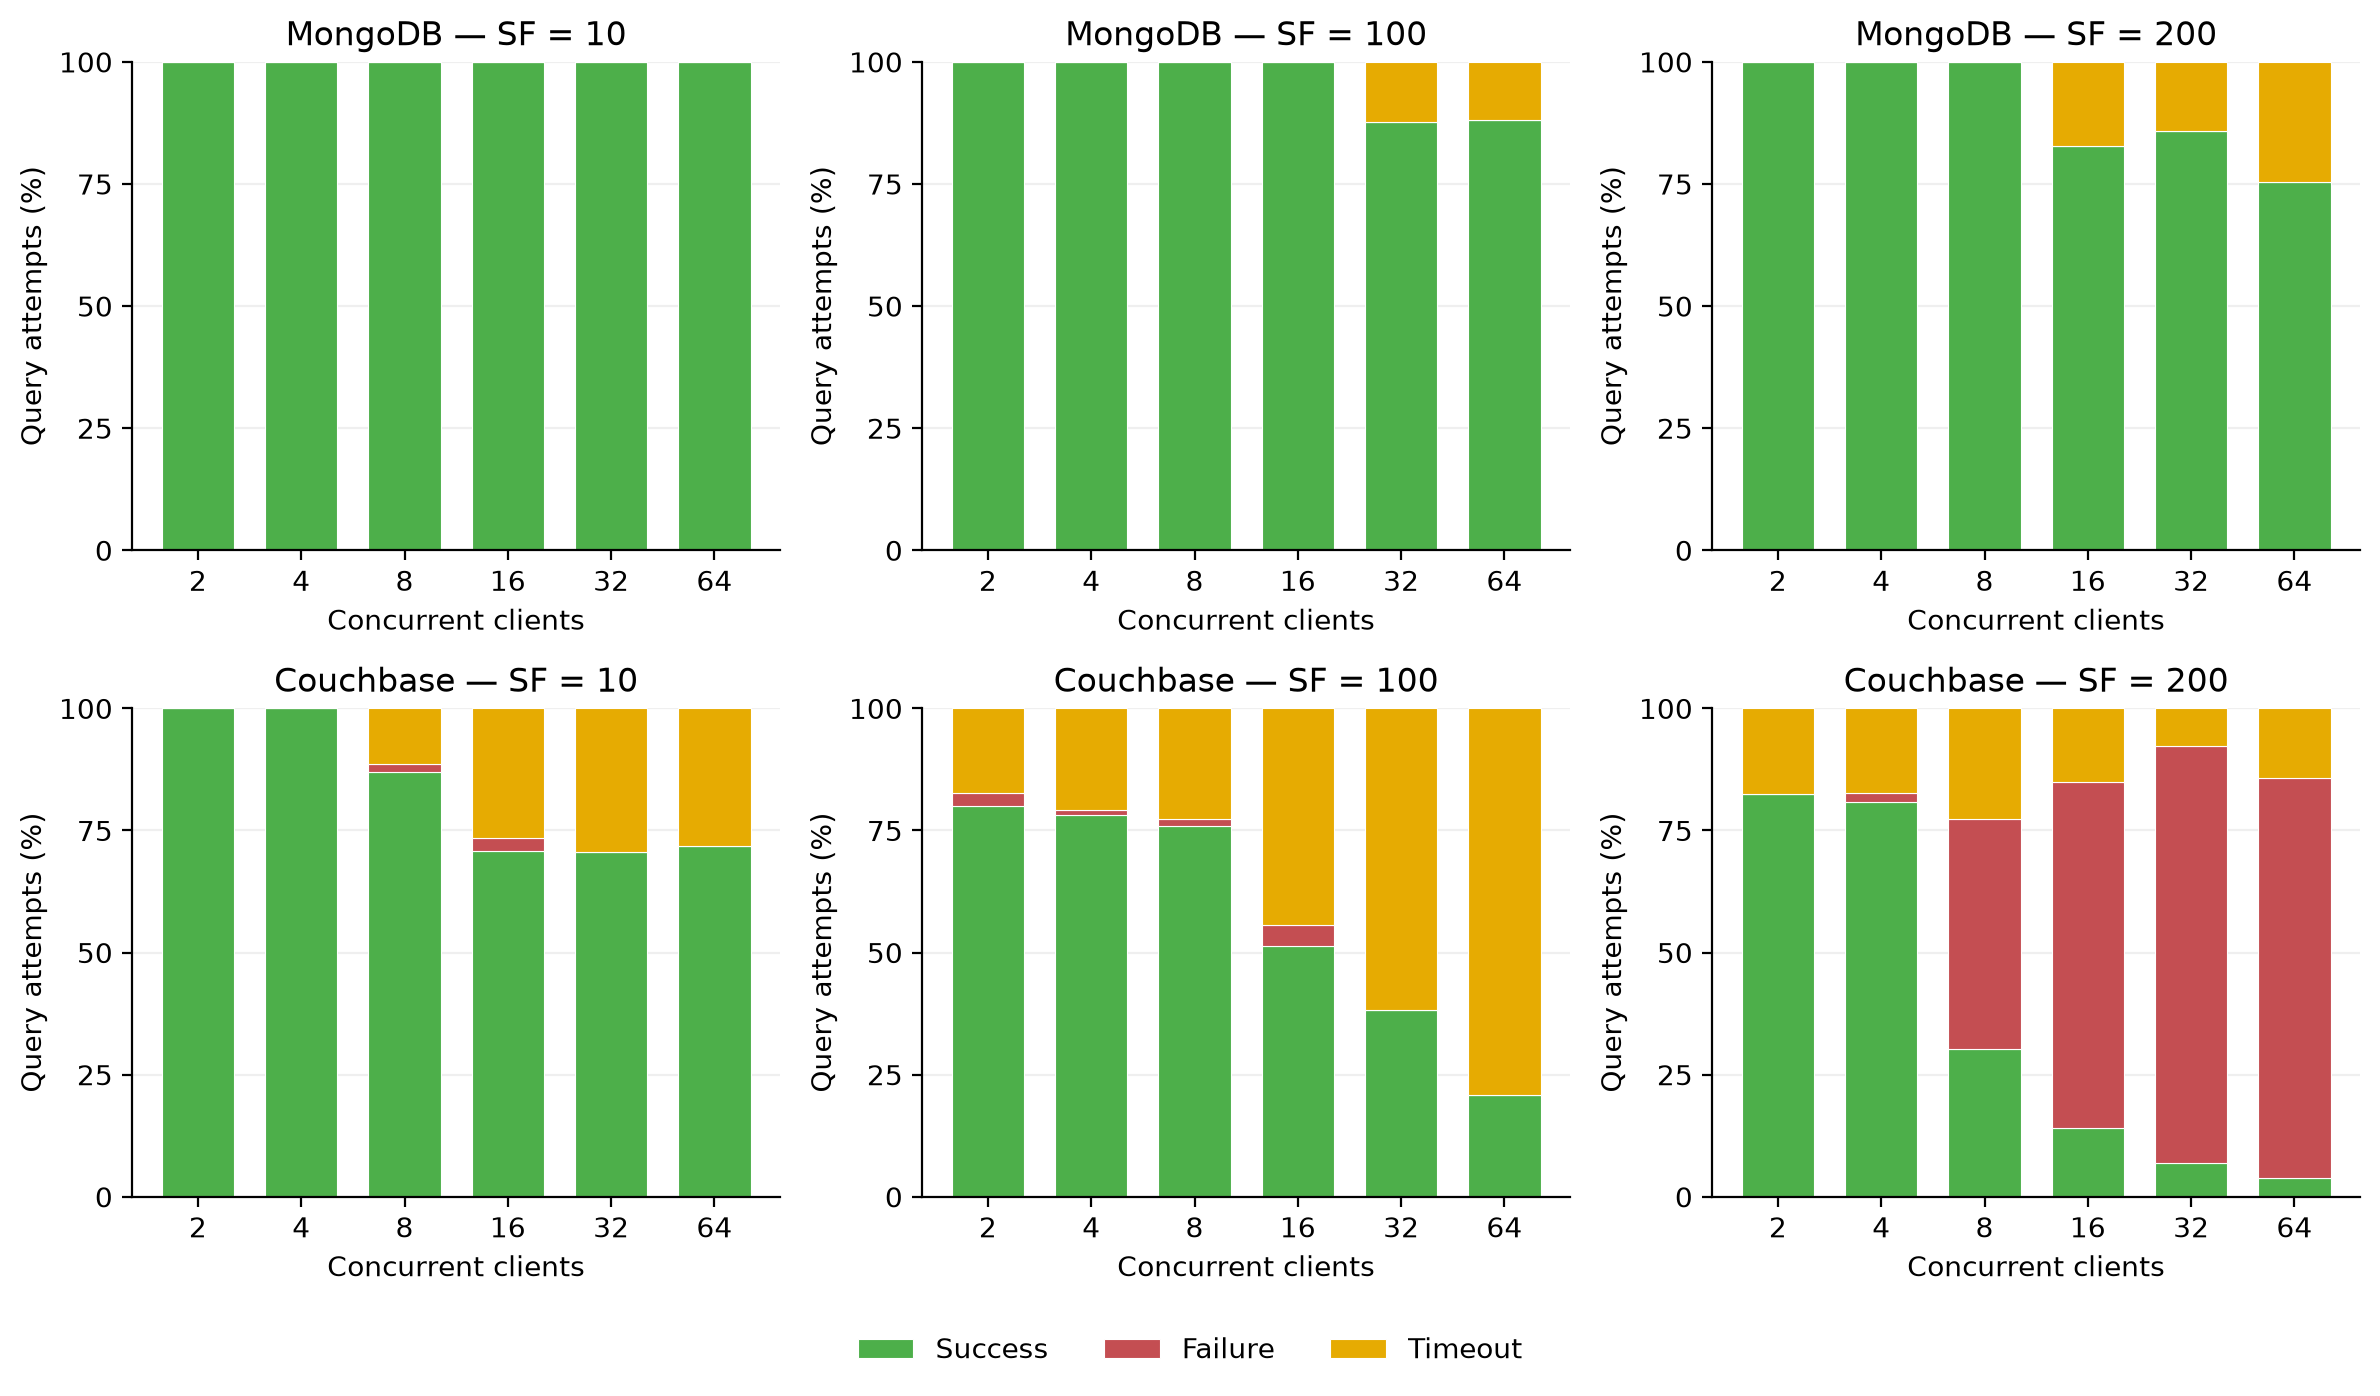

In [4]:
outcome_columns = {"Success": "successes", "Failure": "errors", "Timeout": "timeouts"}
outcome_colors = {"Success": "#4daf4a", "Failure": "#c44e52", "Timeout": "#e6ab02"}
percentages = runs[["backend", "sf", "clients", "repetition", "admitted"]].copy()
for label, column in outcome_columns.items():
    percentages[label] = 100 * runs[column] / runs.admitted
assert np.allclose(percentages[list(outcome_columns)].sum(axis=1), 100)
outcomes = percentages.groupby(["backend", "sf", "clients"])[list(outcome_columns)].mean()
outcomes.to_csv(OUT / "outcome_percentages.csv")
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
x = np.arange(len(CLIENTS))
for i, backend in enumerate(COLORS):
    for j, sf in enumerate(SCALES):
        ax = axes[i, j]
        values = outcomes.loc[(backend, sf)].reindex(CLIENTS)
        bottom = np.zeros(len(CLIENTS))
        for label, color in outcome_colors.items():
            heights = values[label].to_numpy()
            ax.bar(x, heights, 0.7, bottom=bottom, color=color, edgecolor="white", linewidth=0.4, label=label)
            bottom += heights
        ax.set_title(f"{LABELS[backend]} — SF = {sf}")
        ax.set_xticks(x, labels=CLIENTS)
        ax.set_xlabel("Concurrent clients")
        ax.set_ylabel("Query attempts (%)")
        ax.set_ylim(0, 100)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.tick_params(axis="both", labelleft=True, labelbottom=True)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0), frameon=False)
fig.tight_layout(rect=(0, 0.055, 1, 1))
save(fig, "query_outcomes_normalized")


## Option C — compact two-dimensional failure map

Rows are scale factors; columns are client counts. Each cell shows the mean run-level failure percentage. An asterisk means at least one repetition overlapped an OOM kill. This is a compact companion figure; heatmaps hide repetition variability, so the run table and line plots remain important.

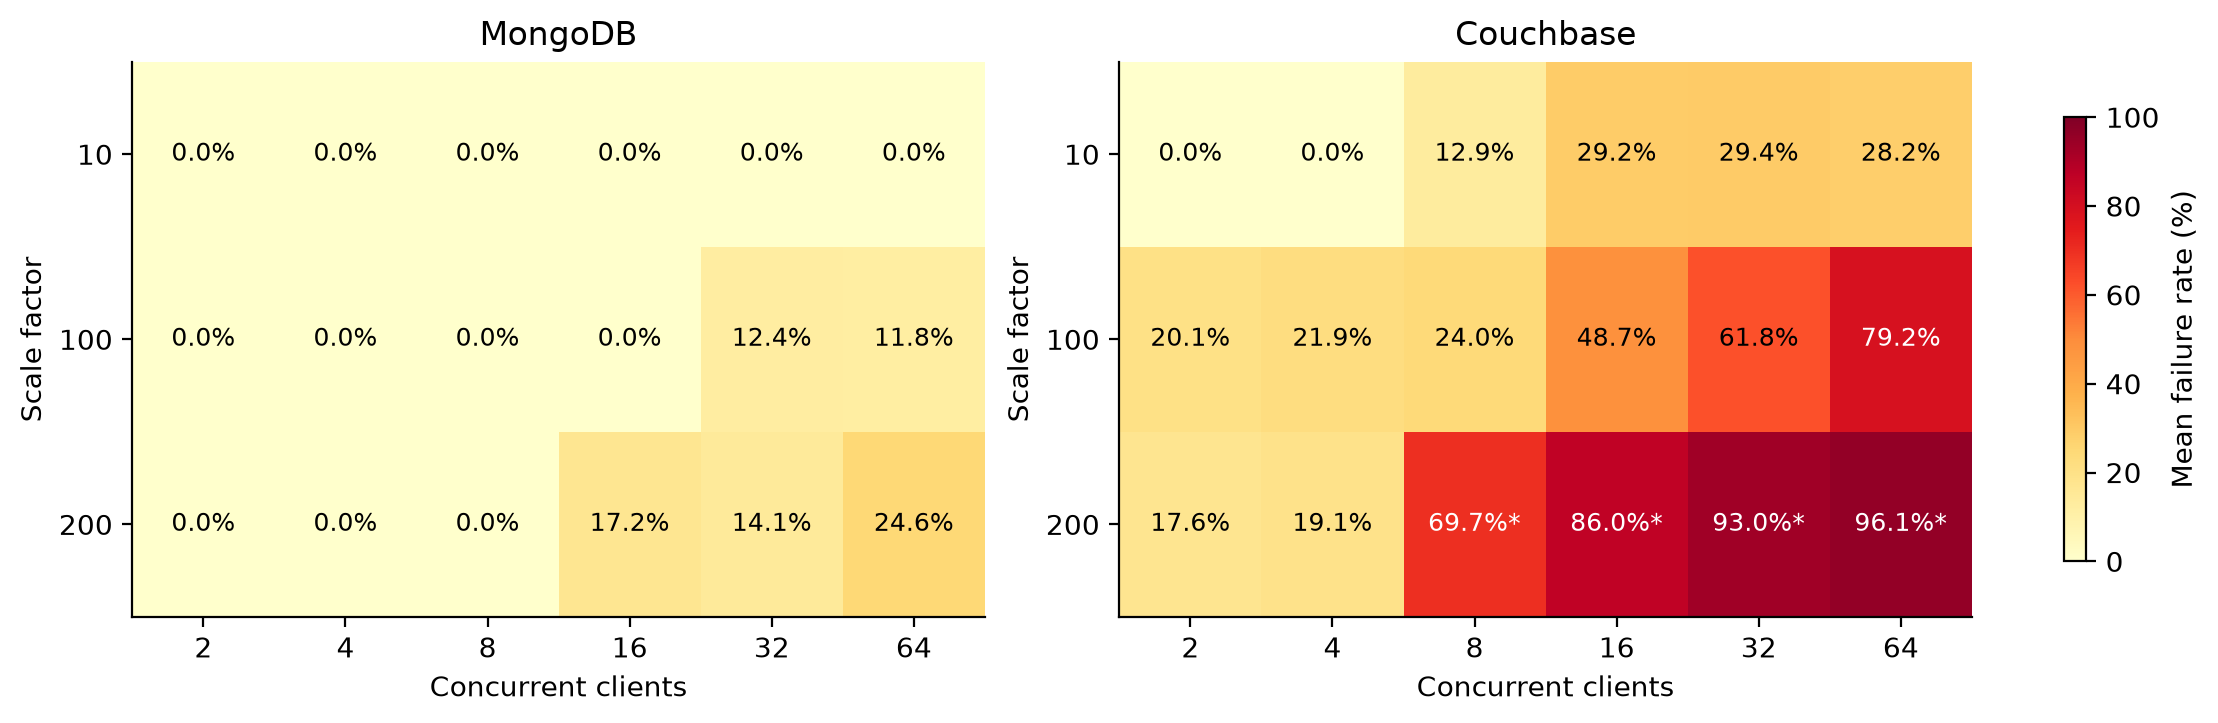

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, backend in zip(axes, COLORS):
    d = runs[runs.backend == backend]
    grid = d.pivot_table(index="sf", columns="clients", values="failure_pct", aggfunc="mean").reindex(
        index=SCALES, columns=CLIENTS
    )
    oom = d.pivot_table(index="sf", columns="clients", values="oom_affected", aggfunc="max").reindex(
        index=SCALES, columns=CLIENTS
    )
    im = ax.imshow(grid, vmin=0, vmax=100, cmap="YlOrRd", aspect="auto")
    for i in range(len(SCALES)):
        for j in range(len(CLIENTS)):
            v = grid.iloc[i, j]
            ax.text(
                j,
                i,
                f"{v:.1f}%" + ("*" if oom.iloc[i, j] else ""),
                ha="center",
                va="center",
                color="white" if v > 65 else "black",
                fontsize=9,
            )
    ax.set_xticks(range(len(CLIENTS)), labels=CLIENTS)
    ax.set_yticks(range(len(SCALES)), labels=SCALES)
    ax.set_xlabel("Concurrent clients")
    ax.set_ylabel("Scale factor")
    ax.set_title(LABELS[backend])
fig.colorbar(im, ax=axes, label="Mean failure rate (%)", shrink=0.8)


## Couchbase SF=200 — duration by outcome

All six client counts and three repetitions pooled, with equal weight per query attempt (not per-run means). Includes queries started during measurement and completed during drain; excludes warm-up-started queries. Error durations measure time until failure, not successful execution latency.


In [6]:
duration_rows = []
for cell in plan["cells"]:
    if cell["backend"] != "couchbase" or cell["scale_factor"] != 200:
        continue
    attempt = state["attempts"][cell["id"]][-1]
    run = DATA / "attempts" / attempt["run_path"].split("/attempts/", 1)[1]
    info = json.loads((run / "info.json").read_text())
    start = info["warmup_seconds"]
    end = start + info["measurement_seconds"]
    for line in (run / "events.jsonl").open():
        event = json.loads(line)
        if event["event"] == "completed" and start <= event["start_seconds"] < end:
            duration_rows.append({"Outcome": event["status"], "duration_s": event["time"]})
duration_summary = (
    pd.DataFrame(duration_rows)
    .groupby("Outcome")["duration_s"]
    .agg(["count", "mean", "median"])
    .reindex(["error", "timeout", "success"])
)
expected = runs[(runs.backend == "couchbase") & (runs.sf == 200)]
assert duration_summary["count"].tolist() == [
    int(expected.errors.sum()),
    int(expected.timeouts.sum()),
    int(expected.successes.sum()),
]
duration_summary.index = ["Error", "Timeout", "Success"]
duration_summary.index.name = "Outcome"
duration_summary.columns = ["Query attempts", "Mean duration (s)", "Median duration (s)"]
duration_summary.to_csv(OUT / "couchbase_s200_duration_by_outcome.csv")
# Format a display-only copy without pandas Styler's optional Jinja2 dependency.
duration_display = duration_summary.copy()
duration_display["Query attempts"] = duration_summary["Query attempts"].map("{:,.0f}".format)
duration_display["Mean duration (s)"] = duration_summary["Mean duration (s)"].map("{:.2f}".format)
duration_display["Median duration (s)"] = duration_summary["Median duration (s)"].map(
    lambda value: f"{value:.5f}" if value < 0.01 else f"{value:.2f}"
)
display(duration_display)


,Query attempts,Mean duration (s),Median duration (s)
Outcome,,,
Error,"5,981",5.83,0.00377
Timeout,453,59.89,60.00
Success,356,19.56,14.91


## OOM audit and configuration summary

Do not drop crash-affected runs silently, and do not compute a “clean-only” backend ranking from a different set of configurations. The table below locates the affected attempts. Exact measurement-phase crash attribution needs more precise wall-clock alignment than the saved workload events provide.

The exported per-query table supports follow-up breakdowns by Q1–Q8. Keep those separate from the mixed-workload plots: averaging all queries and averaging per-query means answer different questions. The three repetitions reuse the same generated dataset and change the workload-selection seed.

In [7]:
display(runs.loc[runs.oom_affected, ["cell", "oom_kills", "throughput_qps", "successful_latency_s", "failure_pct"]])
metrics = ["throughput_qps", "successful_latency_s", "failure_pct"]
summary = runs.groupby(["backend", "sf", "clients"])[metrics].agg(["mean", "min", "max"])
summary.to_csv(OUT / "configuration_summary.csv")
display(summary.round(3))
print(f"Figures (PDF + PNG) and derived tables saved to {OUT}")


,cell,oom_kills,throughput_qps,successful_latency_s,failure_pct
92,couchbase-s200-r1-w8,1,0.100000,17.999285,58.974359
93,couchbase-s200-r1-w16,8,0.166667,17.505691,78.333333
94,couchbase-s200-r1-w32,9,0.133333,17.817854,91.176471
95,couchbase-s200-r1-w64,10,0.144444,15.220355,95.560254
96,couchbase-s200-r2-w64,10,0.100000,11.349927,98.964327
97,couchbase-s200-r2-w32,7,0.133333,21.009826,98.817967
98,couchbase-s200-r2-w16,7,0.133333,13.497235,81.415929
99,couchbase-s200-r2-w8,1,0.105556,17.117451,96.695652
104,couchbase-s200-r3-w8,2,0.100000,24.638854,53.488372
105,couchbase-s200-r3-w16,6,0.155556,22.435941,98.185941


throughput_qps                 successful_latency_s  \
                                mean     min     max                 mean   
backend   sf  clients                                                       
couchbase 10  2                0.302   0.256   0.372                6.805   
              4                0.343   0.294   0.394               12.149   
              8                0.496   0.411   0.556                7.254   
              16               0.541   0.444   0.589                5.695   
              32               0.781   0.733   0.822               19.082   
              64               1.135   1.089   1.178               35.973   
          100 2                0.091   0.072   0.111                9.194   
              4                0.131   0.117   0.144               14.941   
              8                0.198   0.183   0.206               20.705   
              16               0.206   0.194   0.222               15.970   
              32               0.243   0.228   0.250               38.078   
              64               0.235   0.228   0.244               39.613   
          200 2                0.072   0.061   0.083               18.203   
              4                0.102   0.083   0.128               25.983   
              8                0.102   0.100   0.106               19.919   
              16               0.152   0.133   0.167               17.813   
              32               0.148   0.133   0.178               17.785   
              64               0.126   0.100   0.144               17.689   
mongodb   10  2                4.359   4.039   4.639                0.461   
              4                8.052   7.733   8.244                0.498   
              8               14.598  14.456  14.778                0.547   
              16              20.302  20.250  20.394                0.782   
              32              22.100  21.911  22.283                1.434   
              64              19.374  19.294  19.456                3.209   
          100 2                0.413   0.406   0.422                4.748   
              4                0.833   0.817   0.856                4.823   
              8                1.598   1.528   1.700                4.998   
              16               1.633   1.622   1.650                8.912   
              32               2.120   2.072   2.156                6.625   
              64               3.157   3.078   3.206               11.613   
          200 2                0.220   0.183   0.261               10.603   
              4                0.367   0.306   0.433               12.018   
              8                0.744   0.689   0.811               11.470   
              16               0.956   0.922   0.983                5.793   
              32               1.520   1.456   1.578               11.215   
              64               1.835   1.811   1.867               13.139   

                                      failure_pct                  
                          min     max        mean     min     max  
backend   sf  clients                                              
couchbase 10  2         5.171   8.209       0.000   0.000   0.000  
              4        10.269  14.059       0.000   0.000   0.000  
              8         6.144   8.911      12.930  10.811  14.773  
              16        5.520   5.815      29.248  26.846  33.871  
              32       18.660  19.413      29.367  28.293  31.383  
              64       34.492  37.769      28.178  27.178  28.881  
          100 2         8.224   9.781      20.065  16.667  23.529  
              4        13.390  17.365      21.878  16.129  26.923  
              8        19.669  21.409      24.029  22.000  26.087  
              16       15.257  16.737      48.707  47.436  50.000  
              32       36.316  39.755      61.759  59.821  63.636  
              64       38.250  41.278      79.249  78.922  79.904 

Figures (PDF + PNG) and derived tables saved to /Users/thomas/code/JSONBench/analysis/ec2-large-figures


## Couchbase SF=200 — outcomes over time

Rows fix client count; columns keep the three repetitions separate. Stacked histograms count outcomes in 10-second bins **at completion time**, relative to the start of measurement. Only queries started during the 180-second measurement interval are included, matching the population in the normalized bars above; warm-up-started queries are excluded. Shading after 180 seconds marks the drain period. All eight queries are pooled (set `QUERY_FILTER` to e.g. `"Query 8"` to inspect one). Y limits are shared within each row, but differ between client counts to retain detail. These are counts, not percentages: rapid errors can produce large spikes. No exact OOM timestamps are overlaid because the saved run metadata does not establish a precise measurement clock origin.


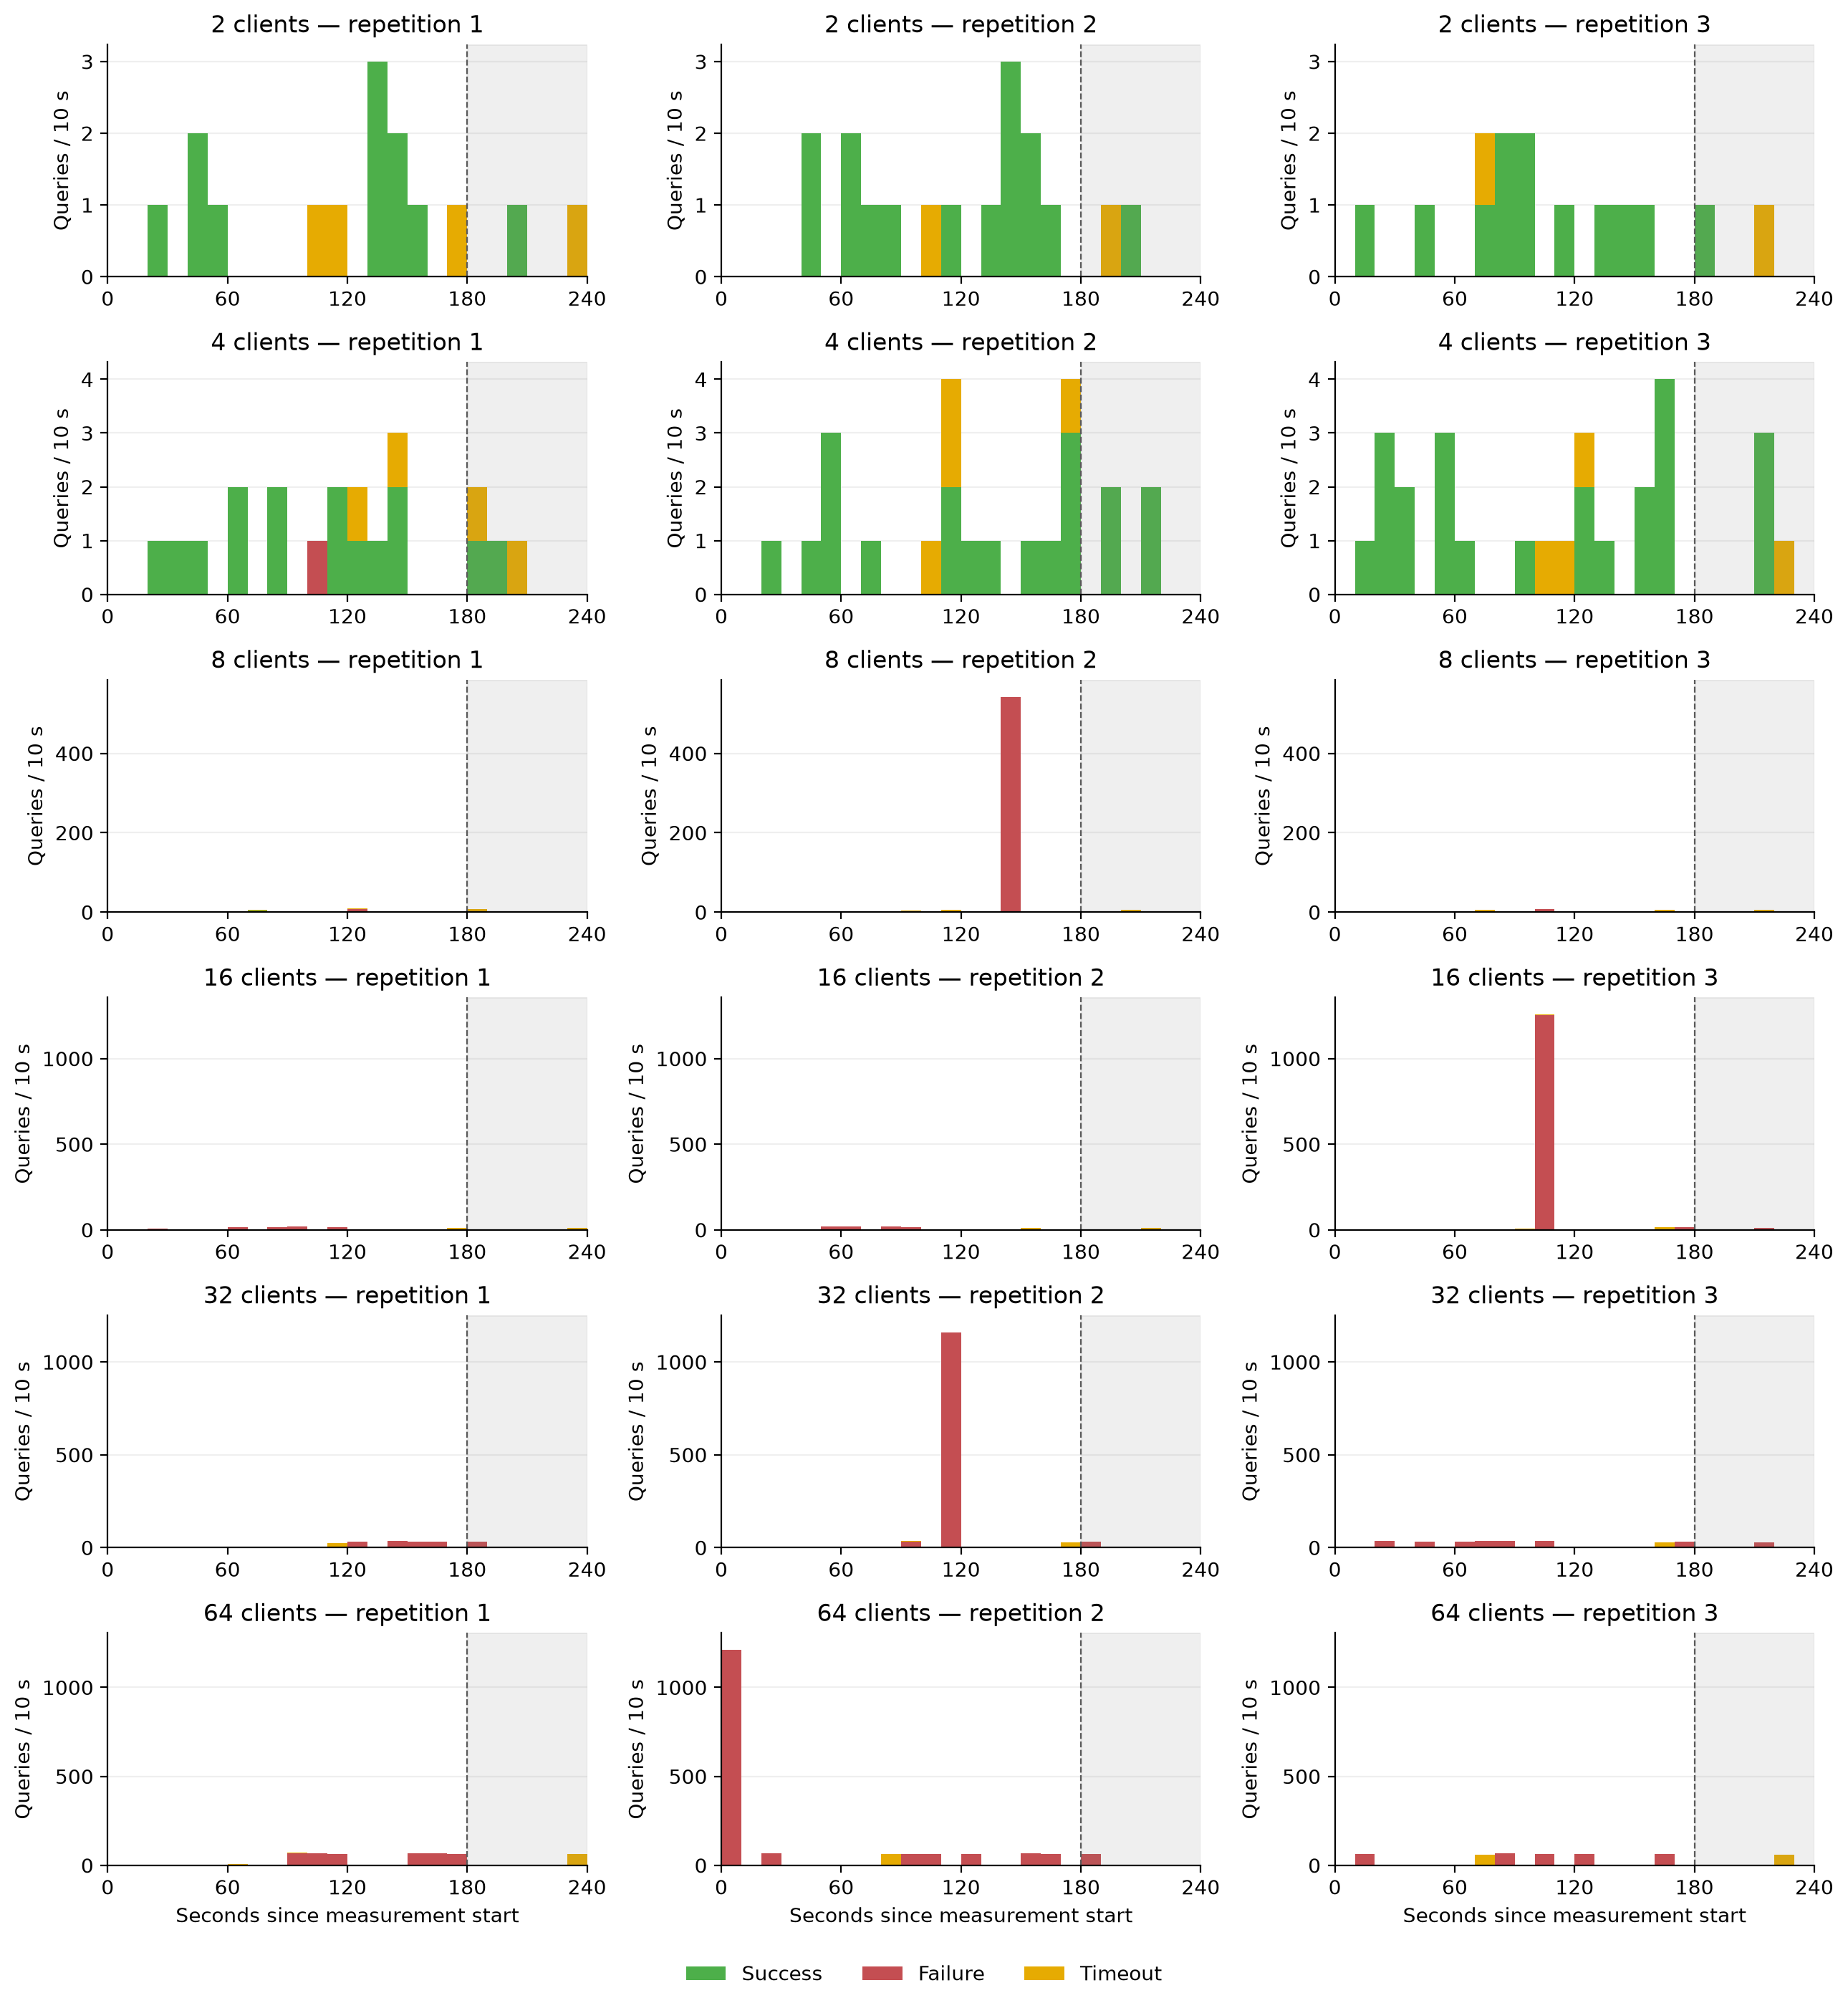

In [8]:
BIN_SECONDS = 10
QUERY_FILTER = None  # None = all eight queries; or e.g. "Query 8"
time_rows = []
for cell in plan["cells"]:
    if cell["backend"] != "couchbase" or cell["scale_factor"] != 200:
        continue
    attempt = state["attempts"][cell["id"]][-1]
    run = DATA / "attempts" / attempt["run_path"].split("/attempts/", 1)[1]
    info = json.loads((run / "info.json").read_text())
    start = info["warmup_seconds"]
    assert info["measurement_seconds"] == 180
    for line in (run / "events.jsonl").open():
        event = json.loads(line)
        if event["event"] != "completed" or not start <= event["start_seconds"] < start + 180:
            continue
        time_rows.append(
            dict(
                clients=cell["workers"],
                repetition=cell["repetition"],
                query=event["name"],
                status=event["status"],
                completion_s=event["finish_seconds"] - start,
            )
        )
timeline = pd.DataFrame(time_rows)
# Check that time histograms cover exactly the same outcomes as the configuration bars.
for (clients, rep), group in timeline.groupby(["clients", "repetition"]):
    expected = runs.query("backend == 'couchbase' and sf == 200 and clients == @clients and repetition == @rep").iloc[0]
    for status, column in [("success", "successes"), ("error", "errors"), ("timeout", "timeouts")]:
        assert group.status.eq(status).sum() == expected[column]
timeline.to_csv(OUT / "couchbase_s200_outcome_events.csv", index=False)
selected = timeline if QUERY_FILTER is None else timeline[timeline["query"].eq(QUERY_FILTER)]
assert len(selected), "No events match QUERY_FILTER"
end = max(180, np.ceil(selected.completion_s.max() / BIN_SECONDS) * BIN_SECONDS)
bins = np.arange(0, end + BIN_SECONDS, BIN_SECONDS)
fig, axes = plt.subplots(6, 3, figsize=(13, 14), sharex=True, sharey="row")
binned_rows = []
for i, clients in enumerate(CLIENTS):
    for j, rep in enumerate([1, 2, 3]):
        ax = axes[i, j]
        group = selected[(selected.clients == clients) & (selected.repetition == rep)]
        bottom = np.zeros(len(bins) - 1)
        for status, label in [("success", "Success"), ("error", "Failure"), ("timeout", "Timeout")]:
            counts, _ = np.histogram(group.loc[group.status == status, "completion_s"], bins=bins)
            assert counts.sum() == group.status.eq(status).sum()
            ax.bar(
                bins[:-1],
                counts,
                width=BIN_SECONDS,
                align="edge",
                bottom=bottom,
                color=outcome_colors[label],
                label=label,
            )
            bottom += counts
            binned_rows.extend(
                dict(clients=clients, repetition=rep, status=status, bin_start_s=float(t), count=int(c))
                for t, c in zip(bins[:-1], counts)
            )
        ax.axvspan(180, end, color="0.5", alpha=0.12)
        ax.axvline(180, color="0.35", linestyle="--", linewidth=0.8)
        ax.set_title(f"{clients} clients — repetition {rep}")
        ax.set_ylabel("Queries / 10 s")
        ax.tick_params(labelleft=True, labelbottom=True)
        ax.set_xlim(0, end)
        ax.set_xticks(np.arange(0, end + 1, 60))
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        if i == 5:
            ax.set_xlabel("Seconds since measurement start")
# Set common row limits after all three panels exist; avoid clipping later repetitions.
for row in axes:
    ymax = max(
        max((patch.get_y() + patch.get_height() for patch in ax.patches if hasattr(patch, "get_height")), default=0)
        for ax in row
    )
    row[0].set_ylim(0, max(1, ymax * 1.08))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.025, 1, 1))
save(fig, "couchbase_s200_outcomes_over_time")
pd.DataFrame(binned_rows).to_csv(OUT / "couchbase_s200_outcome_bins.csv", index=False)


## Healthy SF=10 configurations — execution time by query template

Both databases recorded zero errors and timeouts at 2 and 4 clients across all three repetitions. These panels compare median successful execution time for Q1–Q8, pooling measurement-admitted attempts across the three repetitions (including drain completions). Each attempt has equal weight. Dots show the individual repetition medians; bars show the pooled median, not the mean of those medians. Logarithmic y-axes accommodate differences in query cost. Higher client counts are excluded here because Couchbase recorded timeouts at SF=10 from 8 clients onward. Counts and per-repetition medians are exported alongside the figure.


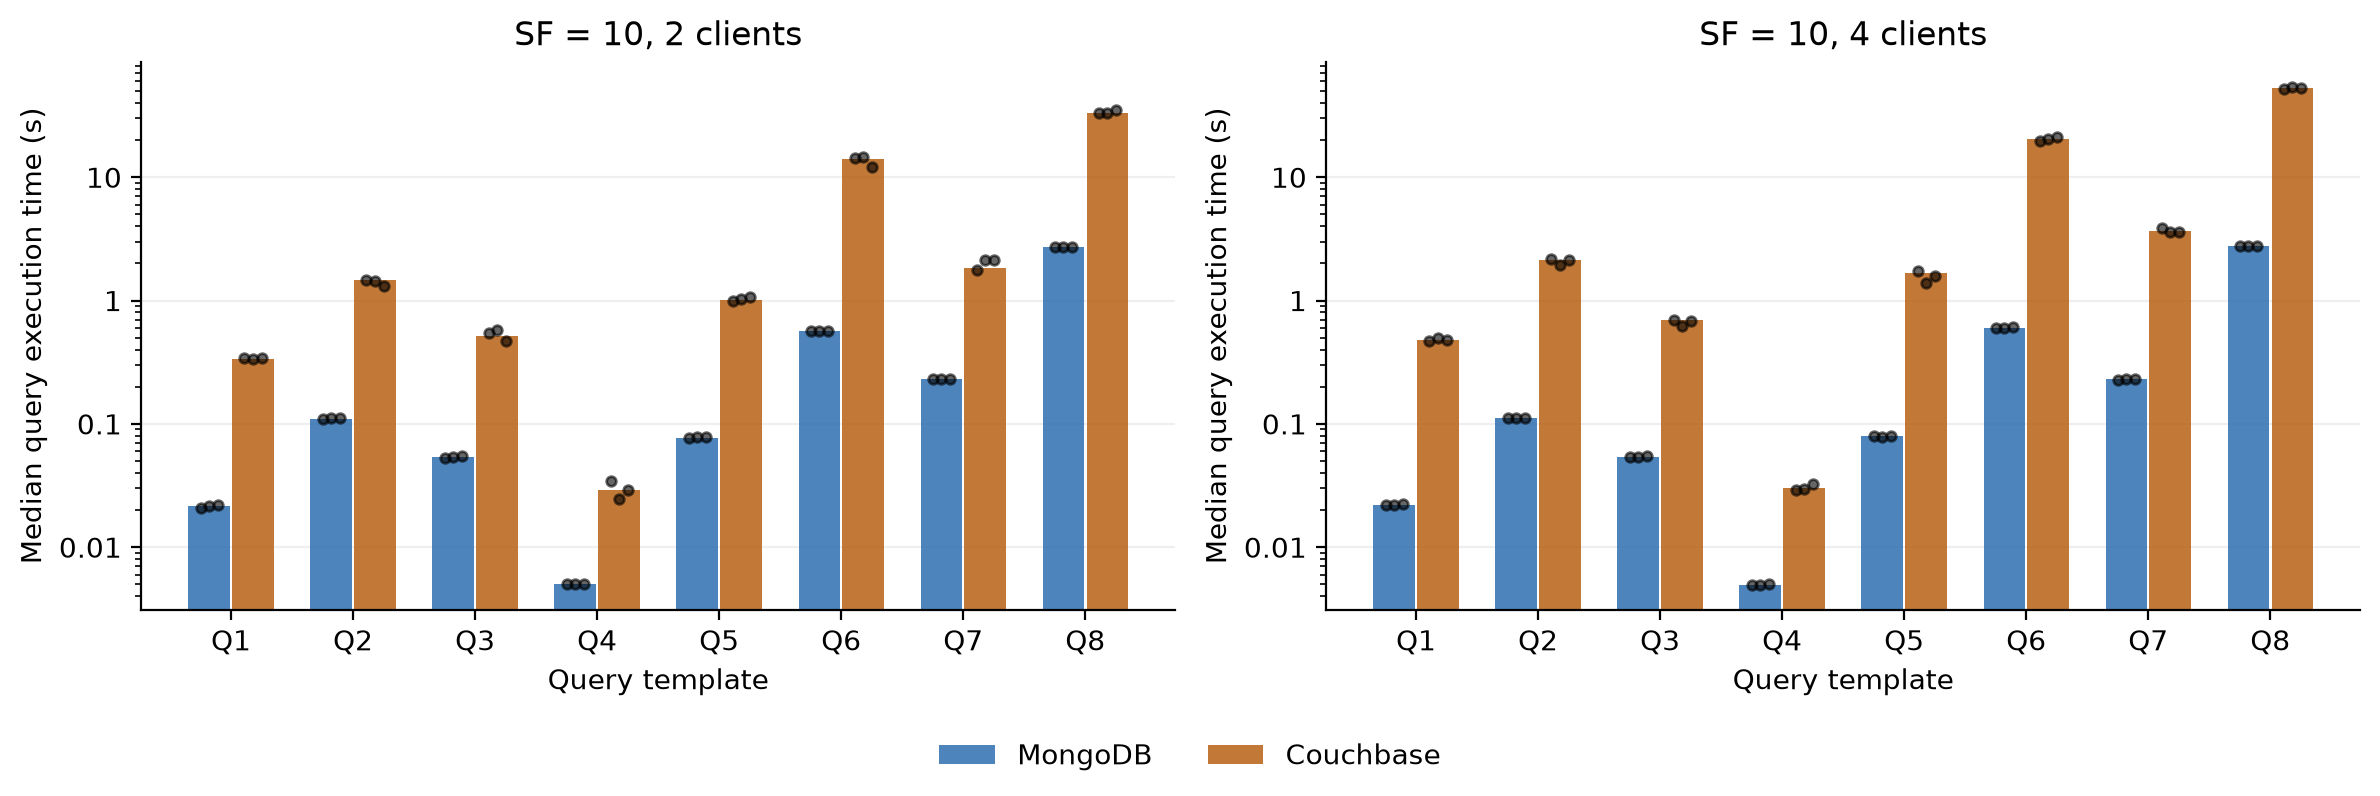

count     median
backend   clients query                    
couchbase 2       Query 1     34   0.337699
                  Query 2     15   1.467805
                  Query 3     16   0.520508
                  Query 4      9   0.029055
                  Query 5     23   1.007987
                  Query 6     22  13.996834
                  Query 7     24   1.825668
                  Query 8     20  33.392385
          4       Query 1     43   0.481732
                  Query 2     11   2.147417
                  Query 3     17   0.690074
                  Query 4     19   0.030129
                  Query 5     21   1.659026
                  Query 6     17  20.342169
                  Query 7     25   3.657819
                  Query 8     32  53.122913
mongodb   2       Query 1    310   0.021485
                  Query 2    280   0.110110
                  Query 3    322   0.053549
                  Query 4    305   0.005027
                  Query 5    255   0.077352
                  Query 6    322   0.568431
                  Query 7    280   0.230358
                  Query 8    280   2.716282
          4       Query 1    566   0.022178
                  Query 2    511   0.110963
                  Query 3    535   0.054238
                  Query 4    553   0.004959
                  Query 5    485   0.079054
                  Query 6    596   0.602224
                  Query 7    545   0.229361
                  Query 8    557   2.753642

In [9]:
healthy_clients = [2, 4]
healthy_runs = runs[(runs.sf == 10) & runs.clients.isin(healthy_clients)]
assert healthy_runs.errors.sum() == 0 and healthy_runs.timeouts.sum() == 0
query_events = []
for cell in plan["cells"]:
    if cell["scale_factor"] != 10 or cell["workers"] not in healthy_clients:
        continue
    attempt = state["attempts"][cell["id"]][-1]
    run = DATA / "attempts" / attempt["run_path"].split("/attempts/", 1)[1]
    info = json.loads((run / "info.json").read_text())
    start = info["warmup_seconds"]
    for line in (run / "events.jsonl").open():
        event = json.loads(line)
        if event["event"] == "completed" and start <= event["start_seconds"] < start + info["measurement_seconds"]:
            assert event["status"] == "success"
            query_events.append(dict(backend=cell["backend"], clients=cell["workers"],
                repetition=cell["repetition"], query=event["name"], duration_s=event["time"]))
query_events = pd.DataFrame(query_events)
assert len(query_events) == healthy_runs.successes.sum()
query_medians = query_events.groupby(["backend", "clients", "query"]).duration_s.agg(["count", "median"])
rep_medians = query_events.groupby(["backend", "clients", "query", "repetition"]).duration_s.agg(["count", "median"])
assert len(query_medians) == 32 and len(rep_medians) == 96
query_medians.to_csv(OUT / "sf10_healthy_query_medians.csv")
rep_medians.to_csv(OUT / "sf10_healthy_query_repetition_medians.csv")
from matplotlib.ticker import FuncFormatter
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
query_names = [f"Query {i}" for i in range(1, 9)]
x = np.arange(8)
for ax, clients in zip(axes, healthy_clients):
    for b, (backend, color) in enumerate(COLORS.items()):
        positions = x + (b - .5) * .36
        values = query_medians.loc[(backend, clients)].reindex(query_names)
        ax.bar(positions, values["median"], width=.34, color=color, label=LABELS[backend], alpha=.8)
        for rep, offset in zip([1, 2, 3], [-.07, 0, .07]):
            dots = rep_medians.xs((backend, clients), level=("backend", "clients")).xs(rep, level="repetition").reindex(query_names)
            ax.scatter(positions + offset, dots["median"], s=12, color="black", alpha=.6, zorder=3)
    ax.set_title(f"SF = 10, {clients} clients")
    ax.set_xticks(x, [f"Q{i}" for i in range(1, 9)])
    ax.set_xlabel("Query template")
    ax.set_ylabel("Median query execution time (s)")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.tick_params(labelleft=True)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, .08, 1, 1))
save(fig, "sf10_healthy_query_medians")
display(query_medians)
